# Begin

Nicholas Alan Gilbert Emperical Exercise #2 10-26-26

### Table of Contents

[Set Up](#Set-Up)

[Data Handling](#Data-Handling)

[Task 1](#Task-1) - Compute Log Returns

[Task 2](#Task-2) - Annual Returns and Volatility

[Task 3](#Task-3) - Data Visualizations

# Set Up

We will import necessary libraries and custom helper-functions written in another file.

In [63]:
%load_ext autoreload
%autoreload 2

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import numpy as np
import ipywidgets

#Custom Helper Functions
import helper.tools as tools

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [125]:
stocks = tools.StockSearch()

In [232]:
stocks.start

datetime.date(2000, 1, 1)

In [233]:
stocks.end

datetime.date(2026, 10, 26)

In [234]:
stocks.tickers

['AAPL', 'TRMD', 'LMT', 'ADBE', 'MSFT', 'NVDA', 'AMD', 'XLF']

In [235]:
df = stocks.data.copy()

[*********************100%***********************]  8 of 8 completed


In [236]:
df

Price            Close                                                  \
Ticker            AAPL        ADBE         AMD         LMT        MSFT   
Date                                                                     
2000-01-03    0.837002   16.274670   15.500000   10.281113   35.377014   
2000-01-04    0.766435   14.909398   14.625000   10.630160   34.181980   
2000-01-05    0.777650   15.204174   15.000000   10.693622   34.542385   
2000-01-06    0.710354   15.328289   16.000000   10.852289   33.385277   
2000-01-07    0.744002   16.072983   16.250000   10.884013   33.821556   
...                ...         ...         ...         ...         ...   
2026-10-19  342.940002  247.089996  538.049988  548.229980  533.520020   
2026-10-20  339.500000  256.730011  534.739990  548.710022  531.869995   
2026-10-21  343.989990  255.059998  552.719971  551.510010  532.950012   
2026-10-22  348.220001  270.549988  507.929993  589.909973  521.080017   
2026-10-23  347.730011  263.820007  516.789978  604.179993  524.510010   

Price                                            Volume                      \
Ticker            NVDA       TRMD        XLF       AAPL      ADBE       AMD   
Date                                                                          
2000-01-03    0.089206        NaN  11.013212  535796800   7384400   7843200   
2000-01-04    0.086825        NaN  10.531758  512377600   7813200   6290200   
2000-01-05    0.083966        NaN  10.449008  778321600  14927200   8204600   
2000-01-06    0.078487        NaN  10.907892  767972800  10221200  11489400   
2000-01-07    0.079798        NaN  11.088438  460734400   8253200   8543400   
...                ...        ...        ...        ...       ...       ...   
2026-10-19  217.089996  37.610001  55.060001   34573200   2924300  20199700   
2026-10-20  216.470001  38.009998  55.720001   35851400   4405100  15187000   
2026-10-21  221.970001  39.349998  56.040001   35614100   3203900  17998600   
2026-10-22  212.210007  38.529999  56.650002   46898900   6847300  28007400   
2026-10-23  210.960007  39.889999  55.900002   39496500   3130800  15135900   

Price                                                          
Ticker          LMT      MSFT       NVDA       TRMD       XLF  
Date                                                           
2000-01-03  3011300  53228400  300912000        NaN   1185699  
2000-01-04  3593500  54119000  300480000        NaN    885705  
2000-01-05  1721200  64059600  188352000        NaN    717181  
2000-01-06  1750700  54976600  120480000        NaN    415832  
2000-01-07  2203200  62013600   71184000        NaN    468149  
...             ...       ...        ...        ...       ...  
2026-10-19  1377800  17994900   98684700  2004800.0  29233000  
2026-10-20  1469900  14576000   79609100  1622600.0  20622300  
2026-10-21  1466000  13940100   87085700  1563100.0  28271900  
2026-10-22  2957700  21266600  125407600  1285200.0  32580900  
2026-10-23  1815900  13671500   79987200  1017700.0  28566600  

[6743 rows x 16 columns]

<Axes: xlabel='Date'>

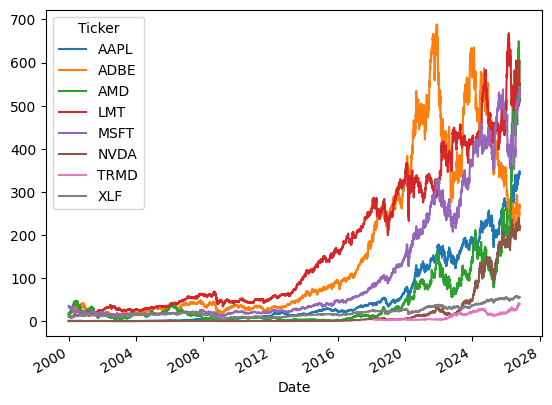

In [237]:
df['Close'].plot()

# Data Handling

[Back to Top](#Begin)

## Log Returns

Log returns are computed under the assumption of *continous time*. It comes from the inverse of the exponential function $e^t$

$\ln(e^t) = t$

Read: the natural-log of $e$ *to the something* is that something.

### Context

Where We Definied Returns Before;

$ r_t = $ return at time period t

$ p_t = $ asset price at time t

$ t = $ time-period eg. daily, weekly, monthly

Asset Return:

$$ r_t = \frac{p_t}{p_{t-1}} - 1$$

Then a series of successive returns of $n$ periods compounded is represented geometrically:

$$r_{\text{cumulative}} := (\prod_{i=1}^{n} 1 + r_i) - 1 = [(1+r_1) \cdot (1+r_2) \cdot (1+r_3) \dots (1+r_n)] - 1$$

This is a more expensive operation, adding 1s to each entry then performing $n$ multiplications.

## Natural Log to the Rescue

Some nice arithmetic properties of using ln() returns is that compounding is additive.

$$\ln\left( \frac{p_t}{p_{t-1}} \right) = \ln( p_t) - \ln( p_{t-1})$$

$$\ln\left( {p_t}\cdot{p_{t-1}} \right) = \ln( p_t) + \ln( p_{t-1})$$

### We Define Log-Returns:

$$r_t := \ln(p_t) - \ln(p_{t-1})$$

$$r_t := \ln(p_{\text{today} } ) - \ln(p_{\text{yesterday} })$$

## Calculation Method

We can apply NumPy's `ln()` function to an entire array of asset prices, then use pandas' `.shift()` method to subract a whole shifted array from the other.

Will look something like this:

```python
log_returns = np.log(data['Close']) - np.log(data['Close']).shift(1)
```

## Missing Data

At this point we will 'produce' a NaN value in our return calculation from our first date, we don't have a previous data point to compute a return from that point. So we'll just drop it. Other stock's will exhbit NaN's, say they weren't listed on an exchange at that point, so no data occurs for them.

## Interpretation

Working with log-returns is nice mathematically. But it will differ from the true return an investor will see if they have their money invested. For example, between 2018-02-26 and 2026-08-28.

### Example

#### AAPL's Average Daily Log-Return: 0.096%

#### AAPL's Average Daily Real Return: 0.123%

# Task 1

# Compute Log-Returns

In [238]:
log_returns = np.log(df['Close']) - np.log(df['Close']).shift(1)
log_returns

Ticker,AAPL,ADBE,AMD,LMT,MSFT,NVDA,TRMD,XLF
Date,,,,,,,,
2000-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-04,-0.088077,-0.087618,-0.058108,0.033387,-0.034364,-0.027063,NaN,-0.044700
2000-01-05,0.014527,0.019578,0.025318,0.005952,0.010489,-0.033476,NaN,-0.007888
2000-01-06,-0.090514,0.008130,0.064539,0.014729,-0.034072,-0.067479,NaN,0.042980
2000-01-07,0.046281,0.047440,0.015504,0.002919,0.012983,0.016562,NaN,0.016416
...,...,...,...,...,...,...,...,...
2026-10-19,-0.001515,0.007678,0.017436,-0.007016,0.008414,0.013729,-0.015566,-0.008320
2026-10-20,-0.010082,0.038272,-0.006171,0.000875,-0.003098,-0.002860,0.010579,0.011916
2026-10-21,0.013139,-0.006526,0.033071,0.005090,0.002029,0.025090,0.034647,0.005727


In [239]:
log_returns.isna().sum(), log_returns[log_returns.index > '2018'].isna().sum()

(Ticker
 AAPL       1
 ADBE       1
 AMD        1
 LMT        1
 MSFT       1
 NVDA       1
 TRMD    4565
 XLF        1
 dtype: int64,
 Ticker
 AAPL     0
 ADBE     0
 AMD      0
 LMT      0
 MSFT     0
 NVDA     0
 TRMD    37
 XLF      0
 dtype: int64)

## Note on NaN Handling

So far we can just ignore the NaNs. They aren't 'in the way' for calculating log-returns at this point. The 'sanity check' above tells us there isn't large holes in the data. I know that ticker TRMD wasn't listed until 2018 compared to our other tickers. So we are missing data for historical reasons. Plus we will have NaN from calculating returns.

If we know some caclulations will choose to 'ignore NaNs' or 'include NaNs', this is what looking up the code documentation is for.


In [240]:
sum_stats = tools.summary_statistics_table(log_returns)

sum_stats

,AAPL,ADBE,AMD,LMT,MSFT,NVDA,TRMD,XLF
Mean,0.000894,0.000413,0.000520,0.000604,0.000400,0.001152,0.001143,0.000241
Median,0.000951,0.000747,0.000000,0.000575,0.000381,0.001378,0.000000,0.000616
Standard-Deviation,0.024859,0.026656,0.038870,0.015886,0.018993,0.036740,0.036179,0.017757
Skewness,-3.917443,-0.565404,-0.085206,-0.120945,-0.090053,-0.208016,1.094497,-0.159887
Kurtosis,115.268262,12.353597,8.187625,9.033611,9.478060,13.031658,28.882672,15.469229
Min,-0.731247,-0.353223,-0.391595,-0.136525,-0.169576,-0.434384,-0.365860,-0.182322
Max,0.142617,0.214885,0.420617,0.137081,0.178692,0.353574,0.497581,0.152394


In [157]:
np.exp(sum_stats.loc['Mean']) - 1

AAPL    0.000895
LMT     0.000604
TRMD    0.001143
Name: Mean, dtype: float64

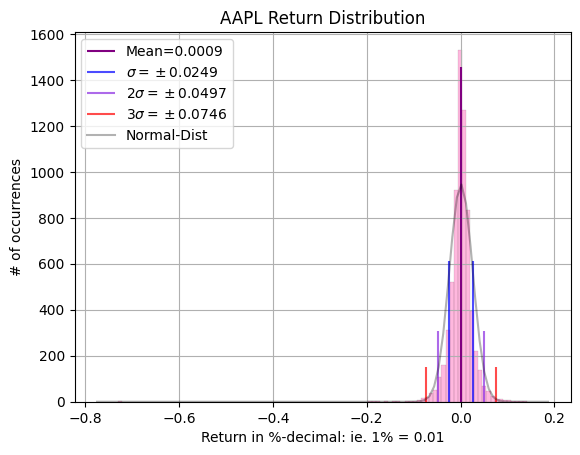

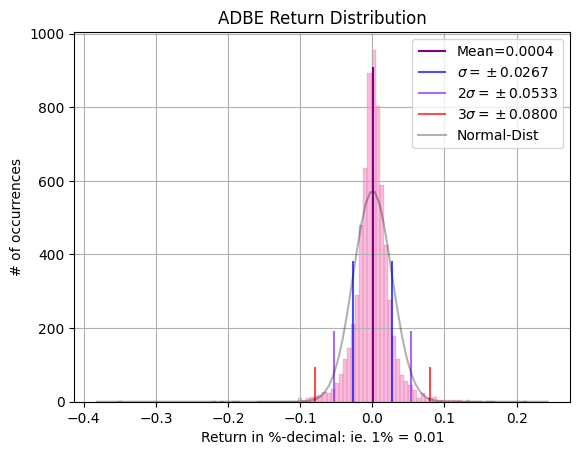

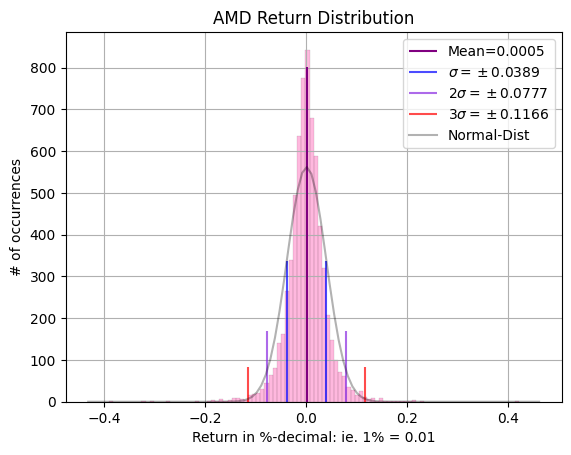

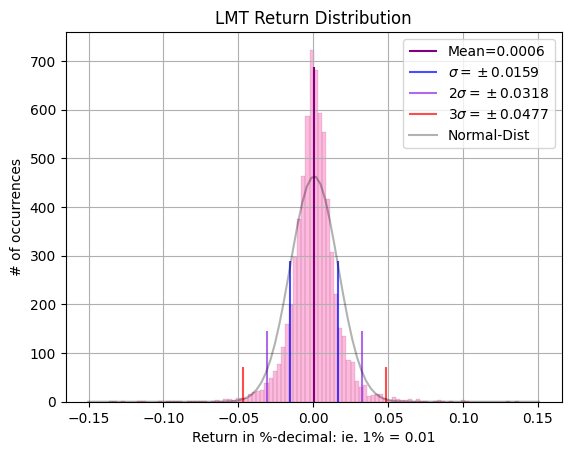

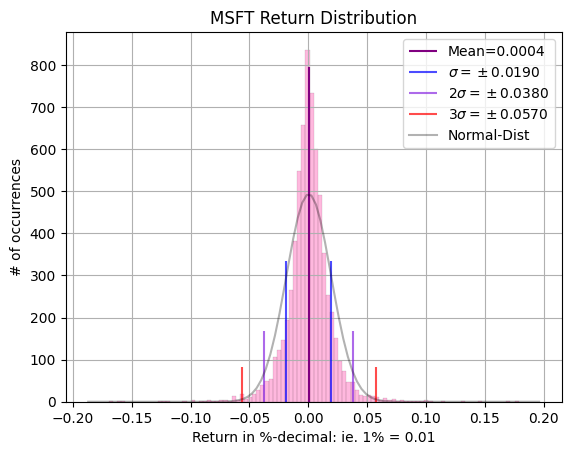

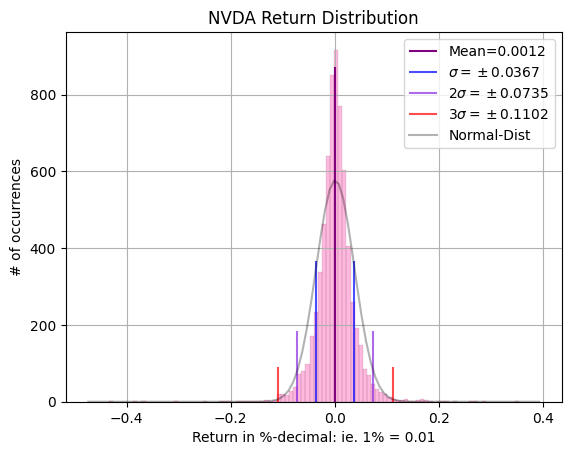

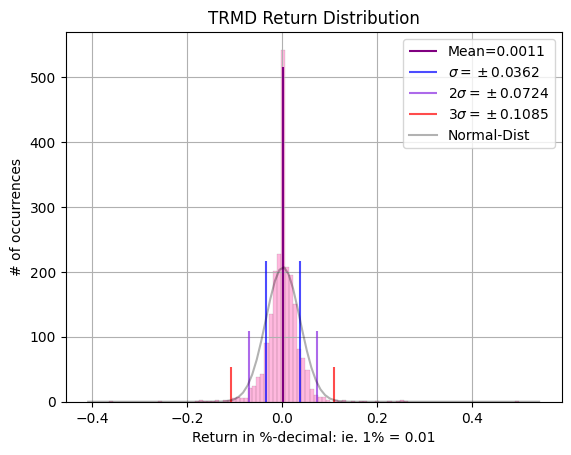

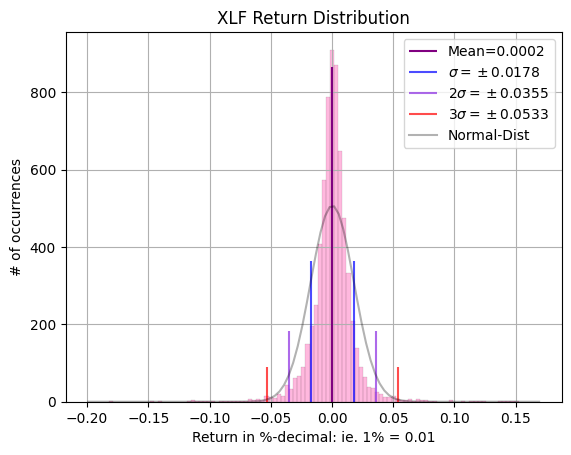

In [241]:
tools.return_histograms(log_returns)

# Task 2

# Annual Volatility

Since log-returns are additive for compounding. We just need to group by year and sum for annualized returns across our time period.

Volatility I will elect to take rolling 90-day windows daily, then compute the average annually, then scale up to annualized by multiplying by $\sqrt{252}.$ Because volatility scales by $\sqrt{\text{time}}$.



In [242]:
df_vol = log_returns.groupby(log_returns.index.year).std() * np.sqrt(252)
df_vol

Ticker,AAPL,ADBE,AMD,LMT,MSFT,NVDA,TRMD,XLF
Date,,,,,,,,
2000,1.013291,0.887646,0.854163,0.444989,0.568322,1.186189,NaN,0.331983
2001,0.623043,0.822725,0.900010,0.325891,0.438939,0.902450,NaN,0.252794
2002,0.489064,0.692421,0.952393,0.367730,0.427174,0.981401,NaN,0.311292
2003,0.368728,0.408799,0.539770,0.249781,0.291202,0.667258,NaN,0.197232
2004,0.396565,0.298697,0.461990,0.174354,0.170639,0.634566,NaN,0.122632
2005,0.387664,0.328790,0.476979,0.152657,0.143365,0.365248,NaN,0.118995
2006,0.381431,0.325087,0.516663,0.161712,0.210594,0.475017,NaN,0.116614
2007,0.375966,0.243814,0.375896,0.226210,0.227153,0.463281,NaN,0.240719
2008,0.587321,0.557204,0.854952,0.392372,0.480072,0.860922,NaN,0.715477


In [243]:
df_yearly = df['Close'].groupby(df.index.year)

In [244]:
yearly_returns = {}

for year in df_yearly:
    yr = year[0]
    df1 = year[1]
    

    lg_rtn = np.log(df1) - np.log(df1).shift(1)

    yearly_returns.update({yr: lg_rtn.sum()})

yearly_return_summary = pd.DataFrame(yearly_returns).T
yearly_return_summary = np.exp(yearly_return_summary) - 1



# Annual Return Summary

Below is a table of annual returns.

## Notable Years:

- 2000 was the Dot-Com era crash that led to large negative returns in technology companies like Apple.
- 2008 was the Great Financial Crisis, so we see stocks with a large negative return that year
- 2020, although Intra-Year 2020 saw a massive crash in Q1, the stock market recovered and rallied as a whole throughout the year as liquidity was pumped in the system and new market participants took discretionary money on stock trading, (ie. Robinhood stock-pickers).
- 2022 we can see the 'Mini Bear Market' of interest rate hiking following COVID



Calculation:

To take log-returns back into percentage returns, we need to exponentiate them.

$$r_{\text{Compounded}} = e^{r_{\text{log}} } - 1$$

In [245]:
yearly_return_summary

Ticker,AAPL,ADBE,AMD,LMT,MSFT,NVDA,TRMD,XLF
2000,-0.734227,0.776116,-0.108871,0.707128,-0.627882,0.399862,0.000000,0.307565
2001,0.472267,-0.334549,0.103304,0.383753,0.527377,3.469297,0.000000,-0.068147
2002,-0.384978,-0.219961,-0.605857,0.258458,-0.228819,-0.828974,0.000000,-0.146386
2003,0.443917,0.528984,1.125535,-0.115966,0.027999,0.884650,0.000000,0.259132
2004,2.026314,0.606887,0.481830,0.115084,0.088101,0.020797,0.000000,0.110176
2005,1.271764,0.198484,0.429239,0.193944,-0.010124,0.550468,0.000000,0.065885
2006,0.134983,0.067497,-0.371914,0.471730,0.128613,0.936682,0.000000,0.169318
2007,1.363723,0.070391,-0.615779,0.161517,0.208429,0.414358,0.000000,-0.195698
2008,-0.561948,-0.489571,-0.697479,-0.186290,-0.437856,-0.755529,0.000000,-0.539958
2009,1.322094,0.597741,3.067227,-0.091734,0.534423,1.144661,0.000000,0.162653


# Task 3

[Back to Top](#Begin)

# Data Visualization

# Data Visualization

<Axes: title={'center': 'Cumulative Return 2018-2026'}, xlabel='Date'>

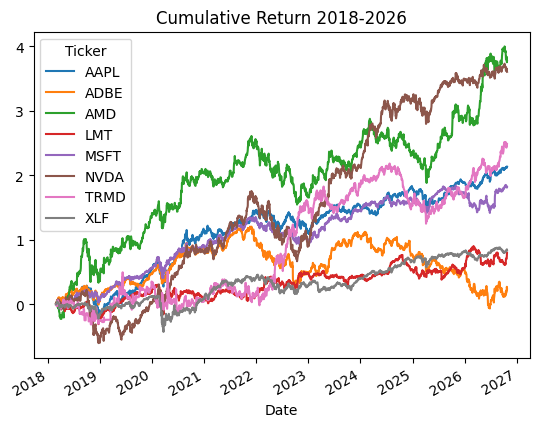

In [246]:
log_returns[log_returns.index > '03-01-2018'].cumsum().plot(title='Cumulative Return 2018-2026')

<Axes: title={'center': 'Rolling 90-Day Volatility'}, xlabel='Date'>

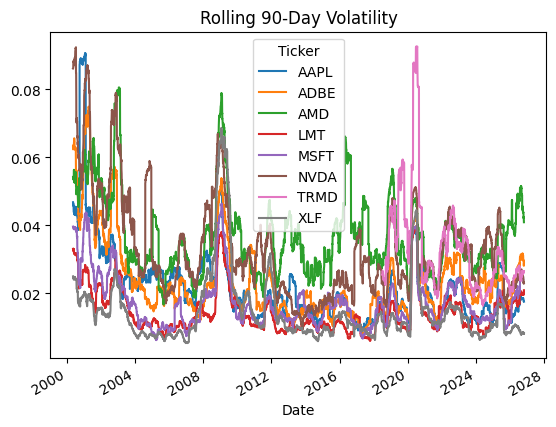

In [248]:
log_returns.rolling(window=90).std().plot(title='Rolling 90-Day Volatility')

# Correlation Matrix

In [249]:
log_returns.corr()

Ticker,AAPL,ADBE,AMD,LMT,MSFT,NVDA,TRMD,XLF
Ticker,,,,,,,,
AAPL,1.000000,0.418488,0.356143,0.179366,0.456748,0.407097,0.099042,0.388956
ADBE,0.418488,1.000000,0.365070,0.214215,0.538793,0.441653,0.049759,0.435302
AMD,0.356143,0.365070,1.000000,0.150427,0.397393,0.497858,0.083286,0.369273
LMT,0.179366,0.214215,0.150427,1.000000,0.238703,0.136005,0.066637,0.392232
MSFT,0.456748,0.538793,0.397393,0.238703,1.000000,0.479276,0.068947,0.489246
NVDA,0.407097,0.441653,0.497858,0.136005,0.479276,1.000000,0.091890,0.362183
TRMD,0.099042,0.049759,0.083286,0.066637,0.068947,0.091890,1.000000,0.121257
XLF,0.388956,0.435302,0.369273,0.392232,0.489246,0.362183,0.121257,1.000000


<Axes: title={'center': 'Correlation with AAPL'}, xlabel='Date'>

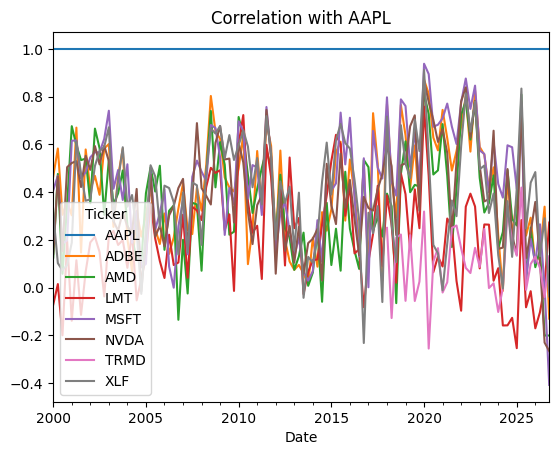

In [250]:
yearly_corr = log_returns.groupby(log_returns.index.to_period("Q")).corr()

yearly_corr.xs('AAPL', level=1).plot(title='Correlation with AAPL')

# Task 4
[Back To Top](#Begin)

## Written Assesment

Presented here is a dynamic and interactive data analysis document. The user can build a portfolio of tickers to perfrom analysis and run the coding cells producing analysis. It all works sequentially, so one can perform another analysis by just going back to the top and choosing a different date range and set of tickers.

Comparing 2-3 stocks, intially I chose Apple, Lockheed Martin, and TORM ( A shipping tanker company). These different tickers exhibit different return and volatility characteristics. You can see that Lockheed Martin exhibits the lowest volatility, as a large stable company in the defense sector, this makes sense. Compared to Apple in the technology sector, we can see Apple's higher-cumulative return matches their higher volatility. If you scan the correlation matrix you can see companies like Apple, Microsoft, Nividia exhibit high correlation overall on a large time-period, which makes sense as they are all technology companies. All these companies exhibit a lower correlation with Lockheed Martin, an aerospace and defense industrial conglomerate. This makes sense, as this sector is more defensive, in the financial sense of the word 'defensive', then technology growth stocks.

What is interesting is quickly in the last few years other blue-chip technology companies have started to show negative correlation with Apple. This seems to be an second-order effect of how the competition surrounding Artificial Intelligence is impacting tech-sector stocks. This sort of observation would warrant a further analysis.

From a macroeconomic perspective you can see the impact of large exogenous events on all of these stocks. Most notably 2000 era Dot-Com crash in Apple. Volatility spikes and negative returns in 2007,2008 due to the Great Financial Crisis. You can also note 2020 COVID-era crash and subsequent rally, followed by 2022 interest-rate hiking adding volatility. More recently you can see 2025 "Liberation Day" volatility spikes from President Trump's aggressive tarrif policy announcements. As an tanker company that deals in oil-markets, you can see Torm's stock rally during 2022 Russian oil embargo, and sinking of oil vessels in Red Sea and 2026 war on Iran. TRMD's exposure to these regional crises has been limited, while their company has benefited from the higher-price point demanded in international markets for shipping tankers.

<Axes: title={'center': 'Correlation with AAPL'}, xlabel='Date'>

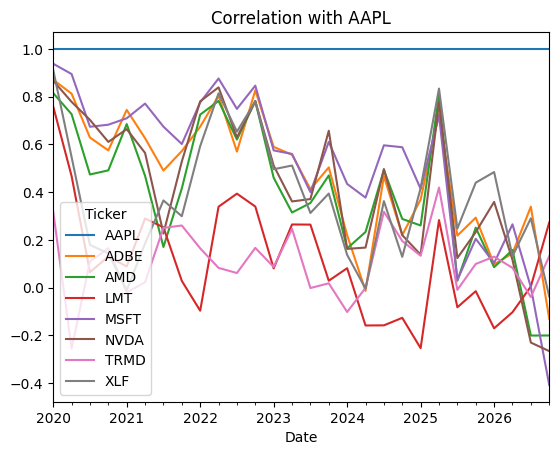

In [251]:
corr_analysis = log_returns[log_returns.index > '2020']
corr_analysis = corr_analysis.groupby(corr_analysis.index.to_period("Q")).corr()

corr_analysis.xs('AAPL', level=1).plot(title='Correlation with AAPL')